In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# 1. Load the processed dataset
df = pd.read_csv('../data/processed/nhanes_processed.csv')

# 2. Define the exact feature sets for the Ablation Study
features_model_A = ['age', 'gender_female', 'bmi', 'waist_circumference']
features_model_B = features_model_A + ['sleep_duration_hrs', 'trouble_sleeping']
target = 'target_diabetes'

# 3. Stratified Train/Test Split (Ensuring exact same rows for both models)
X_A = df[features_model_A]
X_B = df[features_model_B]
y = df[target]

X_train_A, X_test_A, y_train, y_test = train_test_split(X_A, y, test_size=0.2, random_state=42, stratify=y)
X_train_B, X_test_B, _, _ = train_test_split(X_B, y, test_size=0.2, random_state=42, stratify=y)

# 4. Build a robust pipeline to handle missing values and scaling
def build_pipeline():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        # class_weight='balanced' forces the model to pay equal attention to the minority class (Diabetes)
        ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced', max_depth=10))
    ])

print("--- Training Diabetes Models (Ablation Study) ---")

# 5. Train and Evaluate Model A (Baseline)
model_A = build_pipeline()
model_A.fit(X_train_A, y_train)
y_pred_A = model_A.predict(X_test_A)
y_prob_A = model_A.predict_proba(X_test_A)[:, 1]

# 6. Train and Evaluate Model B (With Sleep)
model_B = build_pipeline()
model_B.fit(X_train_B, y_train)
y_pred_B = model_B.predict(X_test_B)
y_prob_B = model_B.predict_proba(X_test_B)[:, 1]

# 7. Print the Comparison
def print_metrics(name, y_true, y_pred, y_prob):
    print(f"\n{name}:")
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_prob):.4f}")
    print(f"F1-Score:  {f1_score(y_true, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")

print_metrics("Model A (Without Sleep)", y_test, y_pred_A, y_prob_A)
print_metrics("Model B (With Sleep)", y_test, y_pred_B, y_prob_B)

--- Training Diabetes Models (Ablation Study) ---

Model A (Without Sleep):
ROC-AUC:   0.7635
F1-Score:  0.4428
Recall:    0.7349
Precision: 0.3169

Model B (With Sleep):
ROC-AUC:   0.7774
F1-Score:  0.4351
Recall:    0.7470
Precision: 0.3069


In [2]:
import joblib
import os

print("--- Training Hypertension Models (Ablation Study) ---")

target_htn = 'target_hypertension'

# 1. Train/Test Split for Hypertension
X_train_A_htn, X_test_A_htn, y_train_htn, y_test_htn = train_test_split(
    X_A, df[target_htn], test_size=0.2, random_state=42, stratify=df[target_htn]
)
X_train_B_htn, X_test_B_htn, _, _ = train_test_split(
    X_B, df[target_htn], test_size=0.2, random_state=42, stratify=df[target_htn]
)

# 2. Train Model A (Without Sleep)
model_A_htn = build_pipeline()
model_A_htn.fit(X_train_A_htn, y_train_htn)
y_pred_A_htn = model_A_htn.predict(X_test_A_htn)
y_prob_A_htn = model_A_htn.predict_proba(X_test_A_htn)[:, 1]

# 3. Train Model B (With Sleep)
model_B_htn = build_pipeline()
model_B_htn.fit(X_train_B_htn, y_train_htn)
y_pred_B_htn = model_B_htn.predict(X_test_B_htn)
y_prob_B_htn = model_B_htn.predict_proba(X_test_B_htn)[:, 1]

# 4. Print the Comparison
print_metrics("Hypertension Model A (Without Sleep)", y_test_htn, y_pred_A_htn, y_prob_A_htn)
print_metrics("Hypertension Model B (With Sleep)", y_test_htn, y_pred_B_htn, y_prob_B_htn)

# 5. Save the winning Model B pipelines for Streamlit deployment
os.makedirs("../models", exist_ok=True)
joblib.dump(model_B, "../models/diabetes_model.pkl")       # From the previous cell
joblib.dump(model_B_htn, "../models/hypertension_model.pkl") # From this cell
print("\n✅ Both Diabetes and Hypertension models successfully saved to the models/ folder!")

--- Training Hypertension Models (Ablation Study) ---

Hypertension Model A (Without Sleep):
ROC-AUC:   0.7726
F1-Score:  0.6485
Recall:    0.7403
Precision: 0.5769

Hypertension Model B (With Sleep):
ROC-AUC:   0.7839
F1-Score:  0.6674
Recall:    0.7662
Precision: 0.5912

✅ Both Diabetes and Hypertension models successfully saved to the models/ folder!


--- Training Advanced XGBoost Models (Hypertension) ---
XGBoost Model A (No Sleep) ROC-AUC: 0.7698
XGBoost Model B (With Sleep) ROC-AUC: 0.7796


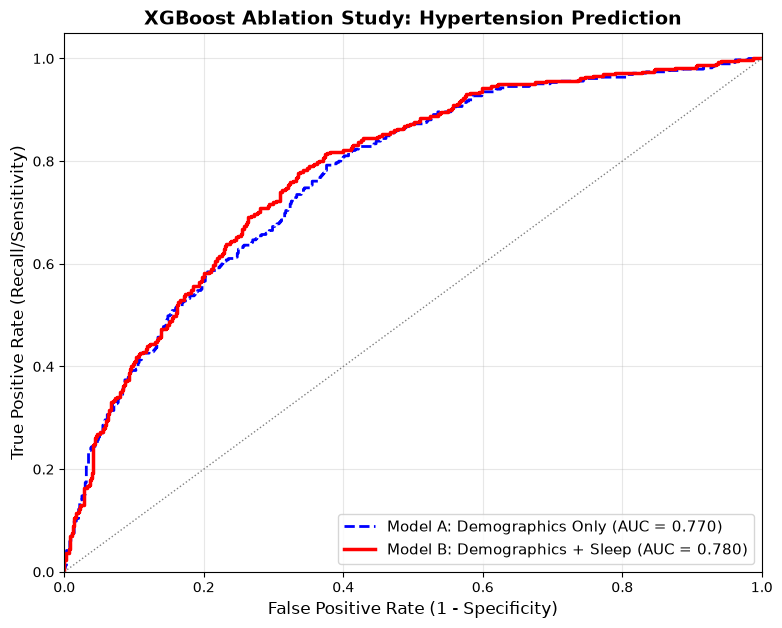

✅ Advanced XGBoost Pipeline saved to models/hypertension_model.pkl


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc, roc_auc_score, f1_score
from xgboost import XGBClassifier
import joblib
import warnings
warnings.filterwarnings('ignore')

print("--- Training Advanced XGBoost Models (Hypertension) ---")

# 1. Load Data & Define Feature Sets
df = pd.read_csv('../data/processed/nhanes_processed.csv')
target = 'target_hypertension'

features_A = ['age', 'gender_female', 'bmi', 'waist_circumference']
features_B = ['age', 'gender_female', 'bmi', 'waist_circumference', 'sleep_duration_hrs', 'trouble_sleeping']

X_train_A, X_test_A, y_train, y_test = train_test_split(df[features_A], df[target], test_size=0.2, random_state=42, stratify=df[target])
X_train_B, X_test_B, _, _ = train_test_split(df[features_B], df[target], test_size=0.2, random_state=42, stratify=df[target])

# Calculate exact imbalance ratio for XGBoost
imbalance_ratio = (len(y_train) - sum(y_train)) / sum(y_train)

# 2. Build the XGBoost Pipeline with advanced hyperparameters
def build_xgb_pipeline():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', XGBClassifier(
            n_estimators=250,           # More trees for deeper learning
            learning_rate=0.05,         # Slower learning to prevent overfitting
            max_depth=5,                # Limit depth to force generalization
            subsample=0.8,              # Use 80% of data per tree
            colsample_bytree=0.8,       # Use 80% of features per tree
            scale_pos_weight=imbalance_ratio, # Mathematically penalize missing the minority class
            random_state=42,
            eval_metric='logloss'
        ))
    ])

# 3. Train Model A (Baseline)
xgb_A = build_xgb_pipeline().fit(X_train_A, y_train)
y_prob_A = xgb_A.predict_proba(X_test_A)[:, 1]
fpr_A, tpr_A, _ = roc_curve(y_test, y_prob_A)
auc_A = auc(fpr_A, tpr_A)

# 4. Train Model B (With Sleep)
xgb_B = build_xgb_pipeline().fit(X_train_B, y_train)
y_prob_B = xgb_B.predict_proba(X_test_B)[:, 1]
fpr_B, tpr_B, _ = roc_curve(y_test, y_prob_B)
auc_B = auc(fpr_B, tpr_B)

print(f"XGBoost Model A (No Sleep) ROC-AUC: {auc_A:.4f}")
print(f"XGBoost Model B (With Sleep) ROC-AUC: {auc_B:.4f}")

# 5. Plot the ROC Curves for Visual Proof
plt.figure(figsize=(9, 7))
plt.plot(fpr_A, tpr_A, color='blue', lw=2, linestyle='--', label=f'Model A: Demographics Only (AUC = {auc_A:.3f})')
plt.plot(fpr_B, tpr_B, color='red', lw=2.5, label=f'Model B: Demographics + Sleep (AUC = {auc_B:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall/Sensitivity)', fontsize=12)
plt.title('XGBoost Ablation Study: Hypertension Prediction', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.show()

# Save the superior XGBoost model to overwrite the Random Forest one
joblib.dump(xgb_B, "../models/hypertension_model.pkl")
print("✅ Advanced XGBoost Pipeline saved to models/hypertension_model.pkl")

In [2]:
pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   ------------ --------------------------- 3.1/9.7 MB 16.5 MB/s eta 0:00:01
   -------------------- ------------------- 5.0/9.7 MB 12.0 MB/s eta 0:00:01
   ----------------------- ---------------- 5.8/9.7 MB 9.5 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.7 MB 7.9 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.7 MB 7.0 MB/s eta 0:00:01
   --------------------------------- ------ 8.1/9.7 MB 6.4 MB/s eta 0:00:01
   ------------------------------------ --- 8.9/9.7 MB 6.0 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.7 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 5.0 MB/s  0:00:02
Note: you may need to restart the kernel to use updated packages.
